# Room 2: depth production

This notebook uses `room_2_simulation.json` beside this notebook to produce `raw.h5` → `photons.h5` → `histogram.h5`, then renders `depth.png` with the shared codebase plotting functions.

Use the project Python environment as the kernel. For native simulation, launch Jupyter from the repository root after activating the runtime (Jupyter must be available):

```bash
source ./activate.sh --full
jupyter lab examples/example_room_2/depth.ipynb
```

Plotting existing histogram data does not require the native runtime. Running the plotting cell overwrites `depth.png`.


In [5]:
from pathlib import Path
import json
import subprocess
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/synthetic_data_generation").is_dir()
             and (p / "examples/example_room_2/room_2_simulation.json").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from within the repository.")
sys.path.insert(0, str(root / "src"))
output_dir = root / "examples/example_room_2"
config_path = output_dir / "room_2_simulation.json"
histogram_path = output_dir / "histogram.h5"
config = json.loads(config_path.read_text())
stages = {stage["command"]: stage["options"] for stage in config["stages"]}
print(json.dumps(config, indent=2))


{
  "output_dir": ".",
  "stages": [
    {
      "command": "simulate",
      "options": {
        "scene": "room_2.usda",
        "output": "{output_dir}/raw.h5",
        "camera_position": [
          3.5887303168332956,
          96.95825285901212,
          67.4154305598385
        ],
        "look_at": [
          3.5887303168332956,
          -103.04174714098788,
          70.0
        ],
        "up": [
          0.0,
          0.0,
          1.0
        ],
        "baseline_offset": [
          5,
          0,
          0
        ],
        "detector_width": 8,
        "detector_height": 8,
        "fov_x": 90,
        "fov_y": 90,
        "width": 100,
        "height": 100,
        "samples_per_ray": 15000,
        "seed": 1
      }
    },
    {
      "command": "pixelize",
      "options": {
        "input": "{output_dir}/raw.h5",
        "output": "{output_dir}/photons.h5",
        "width": 60,
        "height": 60
      }
    },
    {
      "command": "histogram",
      "o

## Generate or reuse the histogram

From the repository root, the equivalent command is:

```bash
synthetic-data run --config examples/example_room_2/room_2_simulation.json
```

The pipeline traces the configured scene using its saved camera and seed, pixelizes photons, and forms a clean histogram using the configured window and bin count. It adds no sensor noise.

Existing data is reused by default. Set `regenerate = True` to rerun all stages and overwrite the simulation outputs. This requires the built native tracer and activated runtime. Both the depth and intensity notebooks use the same histogram, so generation is only needed once.


In [6]:
regenerate = False
if regenerate or not histogram_path.is_file():
    subprocess.run(
        [sys.executable, "-m", "synthetic_data_generation", "run",
         "--config", str(config_path)],
        cwd=root, check=True,
    )
print(f"Using {histogram_path}")


Using /home/peizhao/synthetic_data_generation/examples/example_room_2/histogram.h5


## Load and check the histogram

Check the HDF5 dataset against the local configuration before plotting. If you change generation settings, enable regeneration to refresh the data; shape checks alone cannot detect every stale configuration.


In [7]:
with h5py.File(histogram_path, "r") as handle:
    histogram = handle["stamped_histogram"][:]
expected_shape = (stages["pixelize"]["width"], stages["pixelize"]["height"],
                  stages["histogram"]["bin_number"])
assert histogram.shape == expected_shape, (histogram.shape, expected_shape)
assert np.isfinite(histogram).all() and (histogram >= 0).all()
counts = histogram.sum(axis=-1)
assert counts.sum() > 0, "The histogram contains no photons."
print(f"Histogram: {histogram.shape}; photons in window: {counts.sum():.0f}")


Histogram: (60, 60, 80); photons in window: 4638754


## Form and save the depth preview

Reuse `form_depth_from_histogram()` with its default strongest-bin estimator, and `save_depth_image_png()`. Empty pixels are marked -1 and shown in black. Values are zero-based peak histogram **bin indices**, not calibrated physical distances; ties select the first maximum. The shared depth colour map may differ from the earlier standalone preview.


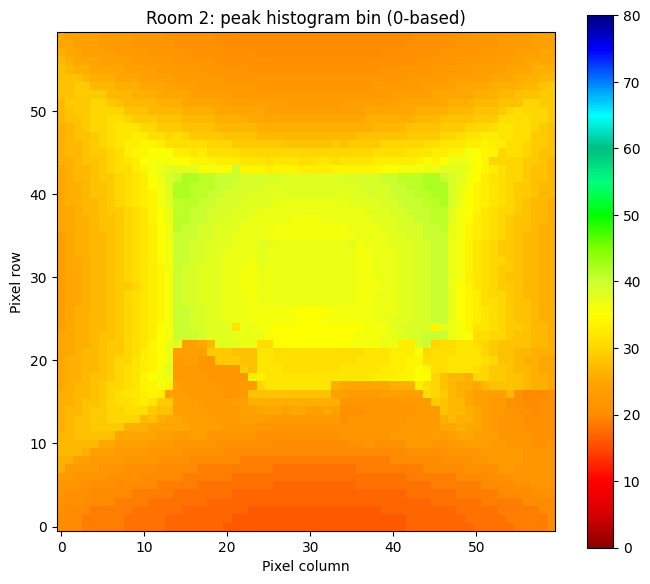

/home/peizhao/synthetic_data_generation/examples/example_room_2/depth.png


In [8]:
from spad_noise_injection.depth import (
    form_depth_from_histogram, save_depth_image_png,
)

depth = form_depth_from_histogram(histogram)
depth[counts == 0] = -1
fig, ax = plt.subplots(figsize=(7, 6))
save_depth_image_png(
    depth, title="Room 2: peak histogram bin (0-based)",
    invalid_value=-1, ax=ax, save_path=output_dir / "depth.png",
    range_max=histogram.shape[-1],
)
ax.set(xlabel="Pixel column", ylabel="Pixel row")
fig.tight_layout()
fig.savefig(output_dir / "depth.png", dpi=180)
plt.show()
plt.close(fig)
print(output_dir / "depth.png")
